# Transfer learning for a small image dataset

A plant nursery has 200 labelled leaf photos of three diseases: leaf spot, blight and powdery mildew. In this
notebook you train a small network from zero, then borrow a ResNet-18 trained on ImageNet, freeze it and train
only a new head, train that head again in plain NumPy, and break a run on purpose with a colour augmentation.
About 15 minutes (the training cells take about 4 minutes together).

Use the free CPU runtime; no GPU is needed. The first ResNet-18 cell downloads its ImageNet weights (45 MB).

## 1. The drawn leaves

We have no real nursery photos. Like the lesson, this notebook draws 200 leaf images with a script: random leaf
size, angle, position, light and noise. Leaf spot and blight have the same dark spots; on a blight leaf the leaf
has also turned yellow. Mildew has soft whitish patches.

The next cell imports the libraries and defines the drawing code. Look for: the torch and torchvision versions.
The lesson's runs used torch 2.15.0 and torchvision 0.29.2. With other versions a loss can differ in the last
decimals.

In [1]:
import time
import numpy as np
import torch
from torch import nn
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| torchvision", torchvision.__version__)

CLASSES = ["leaf_spot", "blight", "mildew"]
SIZE = 112


def draw_leaf(rng, cls):
    H = W = SIZE
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    # bench background: brownish grey with blotchy texture
    bg = np.array([0.45, 0.40, 0.33]) + rng.uniform(-0.08, 0.08, 3)
    img = np.ones((H, W, 3), np.float32) * bg
    img += rng.normal(0, 0.04, (H // 8, W // 8, 1)).repeat(8, 0).repeat(8, 1)
    # leaf ellipse
    cx, cy = W / 2 + rng.uniform(-10, 10), H / 2 + rng.uniform(-10, 10)
    a, b = rng.uniform(34, 48), rng.uniform(18, 28)
    th = rng.uniform(0, np.pi)
    xr = (xx - cx) * np.cos(th) + (yy - cy) * np.sin(th)
    yr = -(xx - cx) * np.sin(th) + (yy - cy) * np.cos(th)
    leaf = (xr / a) ** 2 + (yr / b) ** 2 <= 1
    green = np.array([0.22, 0.50, 0.18]) + rng.uniform(-0.05, 0.05, 3)
    if cls == "blight":
        yellow = np.array([0.78, 0.72, 0.18]) + rng.uniform(-0.05, 0.05, 3)
        t = rng.uniform(0.55, 0.9)
        base = (1 - t) * green + t * yellow
    else:
        base = green
    img[leaf] = base
    # midrib and texture
    vein = leaf & (np.abs(yr) < 1.2)
    img[vein] = img[vein] * 0.8 + 0.12
    img[leaf] += rng.normal(0, 0.03, (leaf.sum(), 1))
    inside = np.argwhere(leaf)
    if cls in ("leaf_spot", "blight"):
        for _ in range(rng.integers(6, 15)):
            py, px = inside[rng.integers(len(inside))]
            r = rng.uniform(1.8, 3.8)
            m = leaf & ((yy - py) ** 2 + (xx - px) ** 2 <= r * r)
            img[m] = np.array([0.25, 0.15, 0.08]) + rng.uniform(-0.04, 0.04, 3)
    else:
        for _ in range(rng.integers(3, 8)):
            py, px = inside[rng.integers(len(inside))]
            r = rng.uniform(5, 10)
            d2 = (yy - py) ** 2 + (xx - px) ** 2
            alpha = (np.exp(-d2 / (2 * r * r)) * rng.uniform(0.5, 0.8) * leaf)[..., None]
            img = img * (1 - alpha) + np.array([0.88, 0.88, 0.85]) * alpha
    img *= rng.uniform(0.75, 1.2)  # greenhouse light
    img += rng.normal(0, 0.035, img.shape)  # sensor noise
    return (np.clip(img, 0, 1) * 255).astype(np.uint8)


def make_dataset(n=200, seed=0):
    rng = np.random.default_rng(seed)
    labels = np.array([i % 3 for i in range(n)])
    rng.shuffle(labels)
    images = np.stack([draw_leaf(rng, CLASSES[c]) for c in labels])
    return images, labels

torch 2.15.0 | torchvision 0.29.2


## 2. 200 photos, 150 to train, 50 held back

The next cell draws the 200 leaves (seed 0), holds back 50 of them to score every run (17 leaf spot, 17 blight,
16 mildew, the same split every run) and shows the first photo of each disease.

Look for: `train 150 val 50` and `val per class [17, 17, 16]`. The blight leaf has the same spots as the leaf
spot leaf; only the leaf itself has turned yellow.

images: (200, 112, 112, 3) uint8
train 150 val 50 val per class [17, 17, 16]


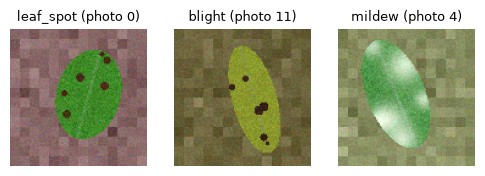

In [2]:
images, labels = make_dataset(200, seed=0)
rng = np.random.default_rng(1)
val_idx = np.concatenate([rng.permutation(np.where(labels == c)[0])[: [17, 17, 16][c]] for c in range(3)])
train_idx = np.setdiff1d(np.arange(200), val_idx)
print("images:", images.shape, images.dtype)
print("train", len(train_idx), "val", len(val_idx), "val per class", [int((labels[val_idx] == c).sum()) for c in range(3)])

fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
for ax, k in zip(axes, range(3)):
    i = int(np.where(labels == k)[0][0])
    ax.imshow(images[i]); ax.set_title(f"{CLASSES[k]} (photo {i})", fontsize=9); ax.axis("off")
plt.show()

## 3. The training tools

This cell turns the photos into tensors and defines what every run uses: the ImageNet normalisation, the safe
augmentations (flips and a small rotation), a batch maker, the small network for the from-scratch run, and
`pretrained(freeze)`, which loads ResNet-18 with its ImageNet weights, freezes every weight if asked, and puts in
a new head with 3 outputs. A new layer trains by default.

Look for: nothing is printed. The cell only defines things.

In [3]:
X = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous()  # uint8 N,3,112,112
Y = torch.from_numpy(labels).long()
NORM = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
TO_FLOAT = v2.ToDtype(torch.float32, scale=True)

SAFE = [v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), v2.RandomRotation(20)]


def batches(idx, aug, bs=32, shuffle=True, g=None):
    order = idx[torch.randperm(len(idx), generator=g).numpy()] if shuffle else idx
    for s in range(0, len(order), bs):
        ix = order[s : s + bs]
        xb = torch.stack([aug(X[i]) for i in ix]) if aug else X[ix]
        yield NORM(TO_FLOAT(xb)), Y[ix]


def small_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        nn.Flatten(), nn.Linear(64, 3))


def pretrained(freeze):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    if freeze:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 3)  # new head, trainable
    return model

## 4. One function for every run

`run` seeds torch, builds the model and optimizer for one of three kinds, trains, and scores the 50 held-back
photos. `"scratch"`: the small network, every weight trains. `"frozen"`: ResNet-18 frozen, the optimizer gets
only the new head. `"finetune"`: every ResNet-18 weight trains, with a smaller learning rate (1e-4) than the head
(1e-3). In a frozen run the backbone stays in eval mode, so its batch-norm statistics stay as learned.

It prints the weights trained, the training loss per epoch, the score and the confusion table: rows are what the
leaf really has, columns what the model called it.

Look for: nothing yet. The next cells call it.

In [4]:
def run(name, kind, aug_list, epochs):
    torch.manual_seed(0)
    g = torch.Generator().manual_seed(0)
    aug = v2.Compose(aug_list) if aug_list else None
    if kind == "scratch":
        model = small_cnn(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    elif kind == "frozen":
        model = pretrained(True); opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
    else:
        model = pretrained(False)
        head = list(model.fc.parameters()); hid = {id(p) for p in head}
        body = [p for p in model.parameters() if id(p) not in hid]
        opt = torch.optim.Adam([{"params": body, "lr": 1e-4}, {"params": head, "lr": 1e-3}])
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    lossf = nn.CrossEntropyLoss()
    t0 = time.time(); losses = []
    for ep in range(epochs):
        model.train()
        if kind == "frozen":
            model.eval(); model.fc.train()  # frozen backbone: keep its batch-norm statistics fixed
        tot, n = 0.0, 0
        for xb, yb in batches(train_idx, aug, g=g):
            opt.zero_grad(); loss = lossf(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item() * len(yb); n += len(yb)
        losses.append(round(tot / n, 3))
    model.eval(); preds = []
    with torch.no_grad():
        for xb, _ in batches(val_idx, None, shuffle=False):
            preds.append(model(xb).argmax(1))
    pred = torch.cat(preds).numpy(); true = labels[val_idx]
    cm = np.zeros((3, 3), int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    print(f"run {name}: {trainable:,} of {total:,} weights trained, {epochs} epochs, {time.time() - t0:.0f} seconds")
    print("train loss per epoch:", losses)
    print(f"held-back photos right: {int((pred == true).sum())} of {len(true)}")
    print("confusion (rows: really leaf_spot, blight, mildew; columns: called leaf_spot, blight, mildew):")
    print(cm)
    return model

## 5. First try: a small network from zero

The small network has 23,779 weights, all starting random. It trains on the 150 photos for 30 epochs with the
safe augmentations. This takes about half a minute.

Look for: the training loss falls from 1.097 to 0.102, so it fits its training photos. But on the held-back
photos it gets only 42 of 50 right, and the last row shows 5 mildew leaves called leaf spot.

In [5]:
scratch = run("scratch", "scratch", SAFE, 30)

run scratch: 23,779 of 23,779 weights trained, 30 epochs, 14 seconds
train loss per epoch: [1.097, 1.077, 1.045, 0.983, 0.893, 0.781, 0.69, 0.608, 0.544, 0.485, 0.446, 0.4, 0.366, 0.35, 0.324, 0.305, 0.285, 0.259, 0.252, 0.241, 0.219, 0.194, 0.177, 0.17, 0.149, 0.139, 0.13, 0.123, 0.12, 0.102]
held-back photos right: 42 of 50
confusion (rows: really leaf_spot, blight, mildew; columns: called leaf_spot, blight, mildew):
[[15  0  2]
 [ 0 16  1]
 [ 5  0 11]]


## 6. ResNet-18, block by block

Before borrowing ResNet-18, count its weights per block. This cell builds it without weights (no download; the
counts do not depend on the values), once with the 1,000-category ImageNet head and once with a new 3-output head.
Blocks without weights (relu, maxpool, avgpool) print 0.

Look for: layer4 alone has 8,393,728 weights. The ImageNet head `fc` has 513,000 (512 inputs times 1,000, plus
1,000); the new head has 1,539 (512 times 3, plus 3). The total falls from 11,689,512 to 11,178,051.

In [6]:
model = resnet18(weights=None)
print("with the ImageNet head:")
for name, m in model.named_children():
    print(f"  {name:8} {sum(p.numel() for p in m.parameters()):>10,}")
print(f"  total    {sum(p.numel() for p in model.parameters()):>10,}")

model.fc = nn.Linear(model.fc.in_features, 3)
print("with a new 3-output head (fc_in_features =", model.fc.in_features, "):")
print(f"  fc       {sum(p.numel() for p in model.fc.parameters()):>10,}")
print(f"  total    {sum(p.numel() for p in model.parameters()):>10,}")

with the ImageNet head:
  conv1         9,408
  bn1             128
  relu              0
  maxpool           0
  layer1      147,968
  layer2      525,568
  layer3    2,099,712
  layer4    8,393,728
  avgpool           0
  fc          513,000
  total    11,689,512
with a new 3-output head (fc_in_features = 512 ):
  fc            1,539
  total    11,178,051


## 7. Borrow ResNet-18, freeze it, train a new head

Same 150 photos, same augmentations, 15 epochs. Every ResNet-18 weight is frozen; only the new head trains. The
first time, this cell downloads the ImageNet weights. It takes about a minute.

Look for: `1,539 of 11,178,051 weights trained` and `held-back photos right: 50 of 50`. The confusion table has
all 50 photos on its diagonal.

In [7]:
frozen = run("frozen", "frozen", SAFE, 15)

run frozen: 1,539 of 11,178,051 weights trained, 15 epochs, 28 seconds
train loss per epoch: [1.42, 0.923, 0.594, 0.382, 0.318, 0.244, 0.183, 0.156, 0.123, 0.121, 0.113, 0.092, 0.086, 0.098, 0.06]
held-back photos right: 50 of 50
confusion (rows: really leaf_spot, blight, mildew; columns: called leaf_spot, blight, mildew):
[[17  0  0]
 [ 0 17  0]
 [ 0  0 16]]


## 8. The frozen network as a feature maker

With the backbone frozen, it only turns each photo into numbers. This cell removes the head (`nn.Identity`),
passes all 200 photos through once with no augmentation, then rescales each column with the training photos'
mean and spread, and adds a constant 1 column that plays the bias.

Look for: `features: (200, 512)`, one row of 512 numbers per photo, and `(200, 513)` with the bias column.

In [8]:
fx = pretrained(True); fx.fc = nn.Identity(); fx.eval()
with torch.no_grad():
    feats = torch.cat([fx(xb) for xb, _ in batches(np.arange(200), None, shuffle=False)]).numpy()
print("features:", feats.shape)

mean, std = feats[train_idx].mean(0), feats[train_idx].std(0) + 1e-6
F = (feats - mean) / std  # standardise with train statistics only
F = np.hstack([F, np.ones((len(F), 1))])  # a constant 1 column plays the bias
print("with the bias column:", F.shape)

features: (200, 512)
with the bias column: (200, 513)


## 9. The new head, from scratch in NumPy

The new head is softmax regression on those fixed features. This is the lesson's `train_head`, with one added
line that prints the loss of each epoch. All weights start at zero; 8 epochs, learning rate 0.01.

Look for: the loss in epoch 0 is 1.0986, which is minus the log of 1/3: with zero weights each disease gets
probability one in three. It then falls every epoch, to 0.2072 in epoch 7. The weights table is (513, 3) = 1,539
numbers, the same count as the torchvision head, and it gets 50 of 50 held-back photos right.

In [9]:
def train_head(leaf_features, disease, epochs, lr):
    weights = np.zeros((leaf_features.shape[1], 3))
    for epoch in range(epochs):
        scores = leaf_features @ weights
        probs = np.exp(scores - scores.max(1, keepdims=True))
        probs /= probs.sum(1, keepdims=True)
        loss = -np.log(probs[np.arange(len(disease)), disease]).mean()
        print(f"epoch {epoch}: loss {loss:.4f}")  # added for the notebook
        probs[np.arange(len(disease)), disease] -= 1
        weights -= lr * leaf_features.T @ probs / len(disease)
    return weights


EPOCHS, LR = 8, 0.01
weights = train_head(F[train_idx], labels[train_idx], EPOCHS, LR)
print("weights shape", weights.shape, "=", weights.size, "numbers learned")
pred = (F[val_idx] @ weights).argmax(1)
print("val correct", int((pred == labels[val_idx]).sum()), "of", len(val_idx))

epoch 0: loss 1.0986
epoch 1: loss 0.6729
epoch 2: loss 0.4843
epoch 3: loss 0.3803
epoch 4: loss 0.3137
epoch 5: loss 0.2675
epoch 6: loss 0.2334
epoch 7: loss 0.2072
weights shape (513, 3) = 1539 numbers learned
val correct 50 of 50


## 10. Broken on purpose: a hue jitter

A colleague adds a fourth augmentation, `ColorJitter(hue=0.5)`, to the frozen run. Everything else is the same.
The run does not crash: it gets worse, quietly. About a minute.

Look for: the score falls from 50 to 38 of 50. The first row shows 11 leaf spot photos called blight. No photo is
called mildew by mistake, and every mildew photo is right: the mistakes are only between the two diseases that
differ by colour.

In [10]:
broken = run("frozen_hue", "frozen", SAFE + [v2.ColorJitter(hue=0.5)], 15)

run frozen_hue: 1,539 of 11,178,051 weights trained, 15 epochs, 29 seconds
train loss per epoch: [1.395, 1.008, 0.727, 0.64, 0.566, 0.469, 0.483, 0.411, 0.386, 0.402, 0.402, 0.348, 0.342, 0.378, 0.335]
held-back photos right: 38 of 50
confusion (rows: really leaf_spot, blight, mildew; columns: called leaf_spot, blight, mildew):
[[ 6 11  0]
 [ 1 16  0]
 [ 0  0 16]]


## 11. What the jitter does to a blight leaf

This cell takes the first blight photo (photo 11) and passes it through `ColorJitter(hue=0.5)` four times
(seeded). `hue=0.5` rotates every colour by a random amount, up to half the colour wheel.

Look for: in some draws the yellowed blight leaf comes out with the colour of a healthy leaf, or a colour no leaf
has. In training, the leaf's colour no longer says anything about the disease.

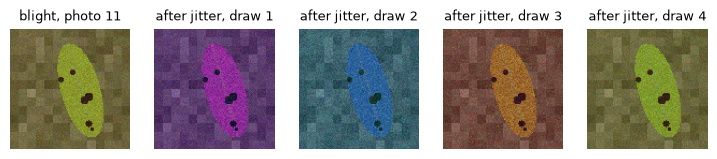

In [11]:
torch.manual_seed(0)
hue = v2.ColorJitter(hue=0.5)
bl = int(np.where(labels == 1)[0][0])
draws = [hue(X[bl]).permute(1, 2, 0).numpy() for _ in range(4)]

fig, axes = plt.subplots(1, 5, figsize=(9, 2.2))
axes[0].imshow(images[bl]); axes[0].set_title(f"blight, photo {bl}", fontsize=9)
for k, (ax, d) in enumerate(zip(axes[1:], draws)):
    ax.imshow(d); ax.set_title(f"after jitter, draw {k + 1}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

## Now change it

Each cell below has one line marked `# <- change this`. Change it, run the cell, and compare.

### Experiment 1: a gentler hue jitter

The same picture as step 11, but you choose how far the jitter may turn the colours.

**What should change:** with 0.5 (as in the broken run) some draws lose the yellowing completely. With 0.05 the
colours turn at most a tenth as far: three draws stay yellowed, but draw 2 already leans toward the green of a
healthy leaf. Blight's yellowing is only a small turn of the colour wheel away from green, so even a small hue
jitter blurs the one thing that separates it from leaf spot. With 0 the four draws are the photo unchanged. The lesson's fix goes further: drop the hue jitter, and if the light
really varies, jitter brightness a little instead (`ColorJitter(brightness=0.2)` alone scored 49 of 50 in the
lesson's runs).

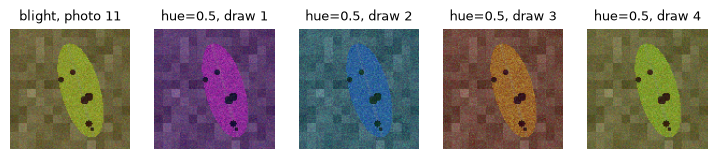

In [12]:
hue_amount = 0.5  # <- change this (try 0.05, then 0)
torch.manual_seed(0)
hue = v2.ColorJitter(hue=hue_amount)
draws = [hue(X[bl]).permute(1, 2, 0).numpy() for _ in range(4)]

fig, axes = plt.subplots(1, 5, figsize=(9, 2.2))
axes[0].imshow(images[bl]); axes[0].set_title(f"blight, photo {bl}", fontsize=9)
for k, (ax, d) in enumerate(zip(axes[1:], draws)):
    ax.imshow(d); ax.set_title(f"hue={hue_amount}, draw {k + 1}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

### Experiment 2: the NumPy head's learning rate

The same `train_head` on the same features, with a learning rate you choose.

**What should change:** with 0.01 (as in step 9) the loss reaches 0.2072 in epoch 7. With 0.001
each step is ten times smaller, and the loss only gets to 0.8080. With 0.1 it falls to 0.0375 after a single
step and to 0.0170 in epoch 7. All three still get 50 of 50 held-back photos right: once the frozen network has
turned the photos into features, these drawn leaves are easy to separate, and the loss only shows how sure the
head is.

In [13]:
lr_try = 0.01  # <- change this (try 0.001, then 0.1)
w_try = train_head(F[train_idx], labels[train_idx], 8, lr_try)
print("learning rate", lr_try, "| val correct", int(((F[val_idx] @ w_try).argmax(1) == labels[val_idx]).sum()), "of", len(val_idx))

epoch 0: loss 1.0986
epoch 1: loss 0.6729
epoch 2: loss 0.4843
epoch 3: loss 0.3803
epoch 4: loss 0.3137
epoch 5: loss 0.2675
epoch 6: loss 0.2334
epoch 7: loss 0.2072
learning rate 0.01 | val correct 50 of 50


### Experiment 3: a fourth disease next spring

The lesson's cheapest answer to a new disease: keep the frozen backbone and give the head one more output. This
cell builds the frozen model with a head of the size you choose and counts what trains.

**What should change:** with 3 diseases the head trains 1,539 weights. With 4 it trains 512 × 4 + 4 = 2,052, and
with 10 it trains 5,130. The frozen part stays 11,176,512 weights whatever the number of diseases: only the head
grows. The real cost of a new disease is labelled photos of it.

In [14]:
n_diseases = 4  # <- change this (try 3, then 10)
m = pretrained(True)
m.fc = nn.Linear(m.fc.in_features, n_diseases)
trains = sum(p.numel() for p in m.parameters() if p.requires_grad)
frozen_w = sum(p.numel() for p in m.parameters() if not p.requires_grad)
print(f"{n_diseases} diseases: head trains {trains:,} weights; frozen backbone {frozen_w:,} weights")

4 diseases: head trains 2,052 weights; frozen backbone 11,176,512 weights


If you have a few minutes more: in step 7, change `"frozen"` to `"finetune"` and run that cell again. Every
weight trains (11,178,051). In the lesson's run it also got 50 of 50, and its training loss reached 0.0: it fits
its 150 photos perfectly, the sign of a model that can memorise them. On a free CPU it takes about 3 to 5 minutes.

## What you should see

- Step 5: the from-scratch network's training loss falls from about 1.097 to about 0.102 over 30 epochs, while
  it gets 42 of 50 held-back photos right.
- Step 7: the frozen ResNet-18 trains 1,539 of 11,178,051 weights and gets 50 of 50 right.
- Step 9: the NumPy head's loss is 1.0986 in epoch 0, before it has learned anything.
- Step 10: with ColorJitter(hue=0.5) added, the score drops to 38 of 50, and the mistakes are leaf spot and
  blight swapped, never mildew.